# Análise de Desempenho de Algoritmos em Ambientes Concorrentes e Paralelos: Um Estudo Comparativo em Java
**Universidade de Fortaleza (UNIFOR) — Centro de Ciências Tecnológicas (CCT) — Ciência da Computação**

Este *Jupyter Notebook* complementa a aplicação gráfica em **Java Swing**, realizando o processamento estatístico e a geração de visualizações de alta resolução a partir dos arquivos CSV exportados pelo framework de testes em Java:
- `resultados/benchmark_resumo.csv`: Estatísticas consolidadas (Média, Desvio Padrão, Mediana, Mínimo, Máximo, Speedup e Eficiência).
- `resultados/benchmark_amostras.csv`: Medições individuais das 5 amostras coletadas para cada configuração.
- `resultados/benchmark_intervalos.csv`: Estudo do impacto da amplitude do intervalo de valores ($k$) em função do tempo.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 0.8

df_resumo = pd.read_csv('resultados/benchmark_resumo.csv')
df_amostras = pd.read_csv('resultados/benchmark_amostras.csv')
df_intervalos = pd.read_csv('resultados/benchmark_intervalos.csv')

df_resumo['CV_Percentual'] = (df_resumo['DesvioPadraoMs'] / df_resumo['MediaMs']) * 100.0
df_resumo['Eficiencia_Percentual'] = df_resumo['Eficiencia'] * 100.0

print(f'Total de configurações avaliadas: {len(df_resumo)}')
print(f'Total de execuções individuais registradas: {len(df_amostras)}')
df_resumo.head(10)

Total de configurações avaliadas: 420
Total de execuções individuais registradas: 2100


,Algoritmo,Modo,Threads,Tamanho,NaturezaDados,IntervaloMax,MediaMs,DesvioPadraoMs,MedianaMs,MinMs,MaxMs,Speedup,Eficiencia,Amostra1Ms,Amostra2Ms,Amostra3Ms,Amostra4Ms,Amostra5Ms,CV_Percentual,Eficiencia_Percentual
0,Quick Sort,Serial,1,10000,ALEATORIO,100000,0.7397,0.5473,0.3871,0.3804,1.6263,1.0000,1.0000,1.6263,0.9203,0.3844,0.3804,0.3871,73.989455,100.00
1,Quick Sort,Paralelo,2,10000,ALEATORIO,100000,0.5874,0.0484,0.5963,0.5257,0.6410,1.2593,0.6297,0.6230,0.5509,0.5963,0.5257,0.6410,8.239700,62.97
2,Quick Sort,Paralelo,4,10000,ALEATORIO,100000,0.7467,0.1898,0.7000,0.5364,1.0011,0.9906,0.2476,0.6196,0.5364,0.7000,1.0011,0.8765,25.418508,24.76
3,Quick Sort,Paralelo,8,10000,ALEATORIO,100000,0.6835,0.0408,0.6942,0.6148,0.7197,1.0823,0.1353,0.7197,0.7063,0.6942,0.6148,0.6824,5.969276,13.53
4,Quick Sort,Paralelo,16,10000,ALEATORIO,100000,0.9949,0.5891,0.8170,0.5544,2.0301,0.7435,0.0465,0.8170,0.8300,2.0301,0.5544,0.7430,59.211981,4.65
5,Merge Sort,Serial,1,10000,ALEATORIO,100000,0.5586,0.0290,0.5496,0.5399,0.6095,1.0000,1.0000,0.6095,0.5496,0.5532,0.5406,0.5399,5.191550,100.00
6,Merge Sort,Paralelo,2,10000,ALEATORIO,100000,0.6724,0.0657,0.6465,0.6147,0.7525,0.8307,0.4154,0.7525,0.6147,0.6157,0.7325,0.6465,9.770970,41.54
7,Merge Sort,Paralelo,4,10000,ALEATORIO,100000,0.6024,0.0366,0.5907,0.5693,0.6652,0.9273,0.2318,0.5901,0.6652,0.5693,0.5966,0.5907,6.075697,23.18
8,Merge Sort,Paralelo,8,10000,ALEATORIO,100000,0.6478,0.0344,0.6444,0.6128,0.6866,0.8622,0.1078,0.6866,0.6444,0.6128,0.6792,0.6160,5.310281,10.78
9,Merge Sort,Paralelo,16,10000,ALEATORIO,100000,0.6716,0.0674,0.6653,0.5947,0.7786,0.8317,0.0520,0.6748,0.5947,0.7786,0.6653,0.6444,10.035736,5.20


## 1. Análise Estatística Descritiva (Conjunto Aleatório — $N = 100.000$ e $N = 1.000.000$)
Abaixo são apresentadas as métricas de tendência central (Média e Mediana), dispersão (Desvio Padrão e Coeficiente de Variação) e desempenho paralelo (Speedup $S_p = T_1 / T_p$ e Eficiência $E_p = S_p / p$).

In [2]:
filtro_100k = df_resumo[(df_resumo['NaturezaDados'] == 'ALEATORIO') & (df_resumo['Tamanho'] == 100000)]
colunas_exibicao = ['Algoritmo', 'Modo', 'Threads', 'MediaMs', 'DesvioPadraoMs', 'MedianaMs', 'CV_Percentual', 'Speedup', 'Eficiencia_Percentual']
display(filtro_100k[colunas_exibicao].round(4))

filtro_1m = df_resumo[(df_resumo['NaturezaDados'] == 'ALEATORIO') & (df_resumo['Tamanho'] == 1000000)]
display(filtro_1m[colunas_exibicao].round(4))

,Algoritmo,Modo,Threads,MediaMs,DesvioPadraoMs,MedianaMs,CV_Percentual,Speedup,Eficiencia_Percentual
60,Quick Sort,Serial,1,6.6594,0.1810,6.5963,2.7180,1.0000,100.00
61,Quick Sort,Paralelo,2,4.1709,0.3165,3.9778,7.5883,1.5966,79.83
62,Quick Sort,Paralelo,4,2.8018,0.0540,2.7786,1.9273,2.3769,59.42
63,Quick Sort,Paralelo,8,3.8534,1.1565,4.3989,30.0125,1.7282,21.60
64,Quick Sort,Paralelo,16,5.1848,0.6774,5.4291,13.0651,1.2844,8.03
65,Merge Sort,Serial,1,11.1256,2.3302,10.1574,20.9445,1.0000,100.00
66,Merge Sort,Paralelo,2,5.8504,0.3111,5.8158,5.3176,1.9017,95.08
67,Merge Sort,Paralelo,4,4.3464,0.2681,4.2601,6.1683,2.5597,63.99
68,Merge Sort,Paralelo,8,3.8854,0.3423,3.9029,8.8099,2.8635,35.79
69,Merge Sort,Paralelo,16,4.2292,0.2716,4.1694,6.4220,2.6307,16.44


,Algoritmo,Modo,Threads,MediaMs,DesvioPadraoMs,MedianaMs,CV_Percentual,Speedup,Eficiencia_Percentual
90,Quick Sort,Serial,1,96.6759,14.9401,100.2128,15.4538,1.0000,100.00
91,Quick Sort,Paralelo,2,44.9952,1.7567,45.8761,3.9042,2.1486,107.43
92,Quick Sort,Paralelo,4,27.8030,3.0495,27.0386,10.9682,3.4772,86.93
93,Quick Sort,Paralelo,8,23.2967,3.3324,22.8524,14.3042,4.1498,51.87
94,Quick Sort,Paralelo,16,22.5724,1.5825,22.4067,7.0108,4.2829,26.77
95,Merge Sort,Serial,1,121.3370,5.6050,121.2161,4.6194,1.0000,100.00
96,Merge Sort,Paralelo,2,59.6035,0.3046,59.4241,0.5110,2.0357,101.79
97,Merge Sort,Paralelo,4,37.0103,2.0805,37.7822,5.6214,3.2785,81.96
98,Merge Sort,Paralelo,8,29.0426,1.9045,28.0502,6.5576,4.1779,52.22
99,Merge Sort,Paralelo,16,29.1622,2.2354,27.8081,7.6654,4.1608,26.00


## 2. Escalabilidade: Tempo de Execução em Função do Tamanho do Vetor ($N$)
Comparamos o comportamento assintótico dos quatro algoritmos (*Quick Sort*, *Merge Sort*, *Counting Sort* e *Bubble Sort*) em execução Serial (1 Thread) e Paralela (8 e 16 Threads).

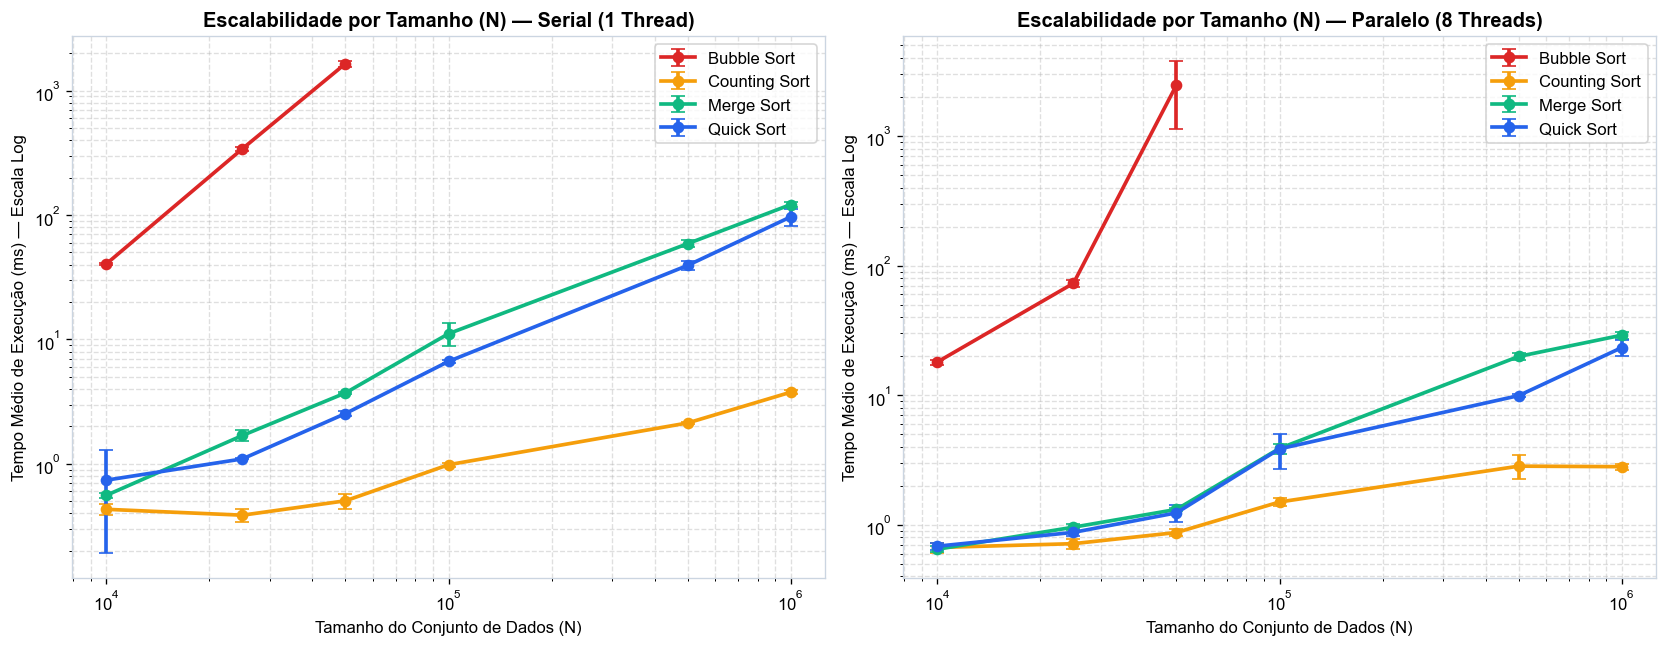

In [3]:
cores = {
    'Quick Sort': '#2563EB',
    'Merge Sort': '#10B981',
    'Counting Sort': '#F59E0B',
    'Bubble Sort': '#DC2626'
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for idx, thr in enumerate([1, 8]):
    ax = axes[idx]
    sub = df_resumo[(df_resumo['NaturezaDados'] == 'ALEATORIO') & (df_resumo['Threads'] == thr)]
    for alg, grupo in sub.groupby('Algoritmo'):
        grupo = grupo.sort_values('Tamanho')
        ax.errorbar(
            grupo['Tamanho'], grupo['MediaMs'], yerr=grupo['DesvioPadraoMs'],
            label=alg, color=cores.get(alg, '#333'), marker='o', linewidth=2.2, capsize=4
        )
    modo_str = 'Serial (1 Thread)' if thr == 1 else f'Paralelo ({thr} Threads)'
    ax.set_title(f'Escalabilidade por Tamanho (N) — {modo_str}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Tamanho do Conjunto de Dados (N)')
    ax.set_ylabel('Tempo Médio de Execução (ms) — Escala Log')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.grid(True, which='both', linestyle='--', alpha=0.4)
    ax.legend()

plt.tight_layout()
plt.show()

## 3. Análise de Speedup ($S_p$) e Eficiência Paralela ($E_p$) por Número de Threads
Investigação do ganho de desempenho ao variar a disponibilidade de núcleos de processamento ($1, 2, 4, 8, 16$ threads).

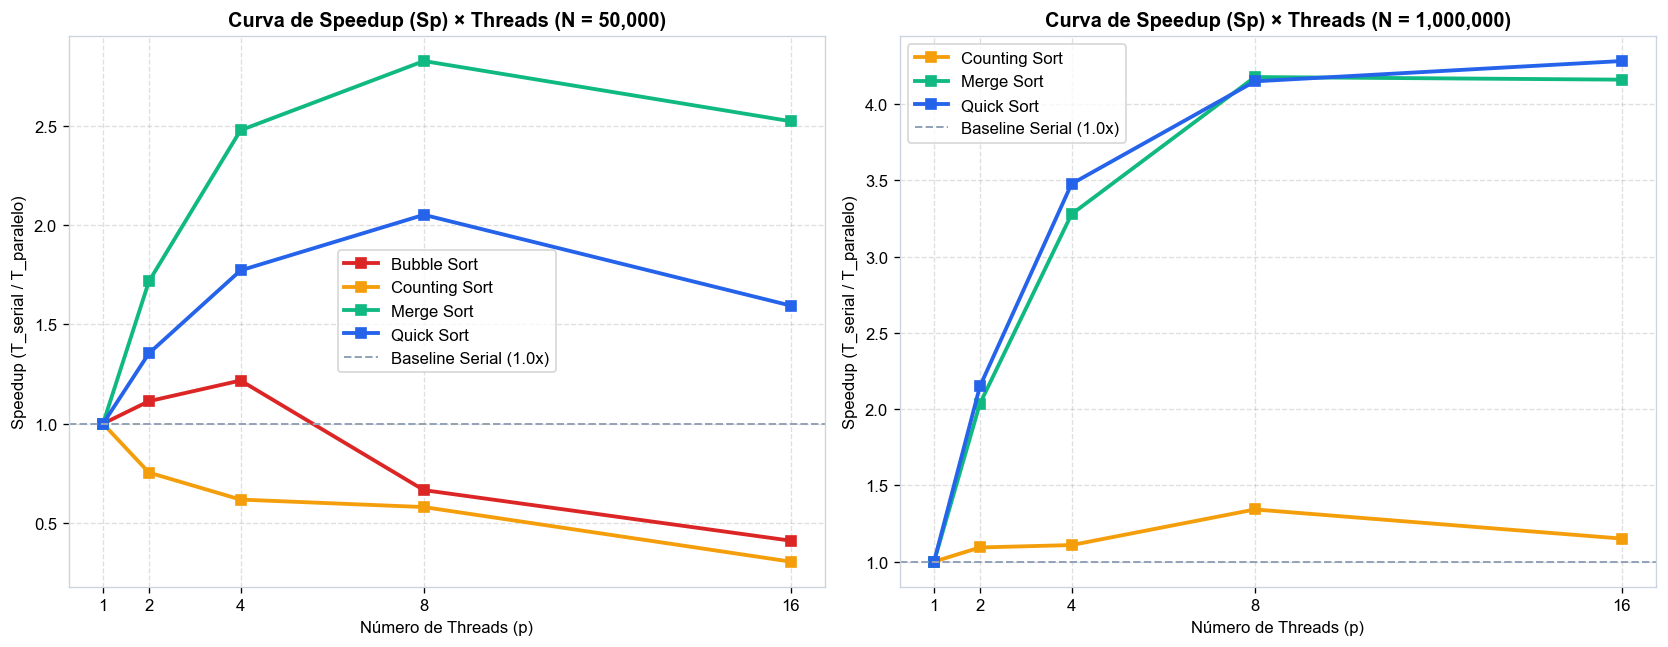

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Speedup para N = 50.000 (inclui Bubble Sort Odd-Even) e N = 1.000.000 (algoritmos rápidos)
for idx, tam in enumerate([50000, 1000000]):
    ax = axes[idx]
    sub = df_resumo[(df_resumo['NaturezaDados'] == 'ALEATORIO') & (df_resumo['Tamanho'] == tam)]
    for alg, grupo in sub.groupby('Algoritmo'):
        grupo = grupo.sort_values('Threads')
        ax.plot(
            grupo['Threads'], grupo['Speedup'],
            label=alg, color=cores.get(alg, '#333'), marker='s', linewidth=2.3
        )
    ax.axhline(1.0, color='#94A3B8', linestyle='--', linewidth=1.2, label='Baseline Serial (1.0x)')
    ax.set_title(f'Curva de Speedup (Sp) × Threads (N = {tam:,})', fontsize=12, fontweight='bold')
    ax.set_xlabel('Número de Threads (p)')
    ax.set_ylabel('Speedup (T_serial / T_paralelo)')
    ax.set_xticks([1, 2, 4, 8, 16])
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend()

plt.tight_layout()
plt.show()

## 4. Impacto da Natureza dos Dados e do Intervalo de Valores ($k$)
Avaliamos como a distribuição inicial dos elementos (`ALEATORIO`, `INVERSAMENTE_ORDENADO`, `QUASE_ORDENADO`, `POUCOS_UNICOS`) e a variação da amplitude máxima de valores $k \in [1.000, 10.000.000]$ afetam cada algoritmo.

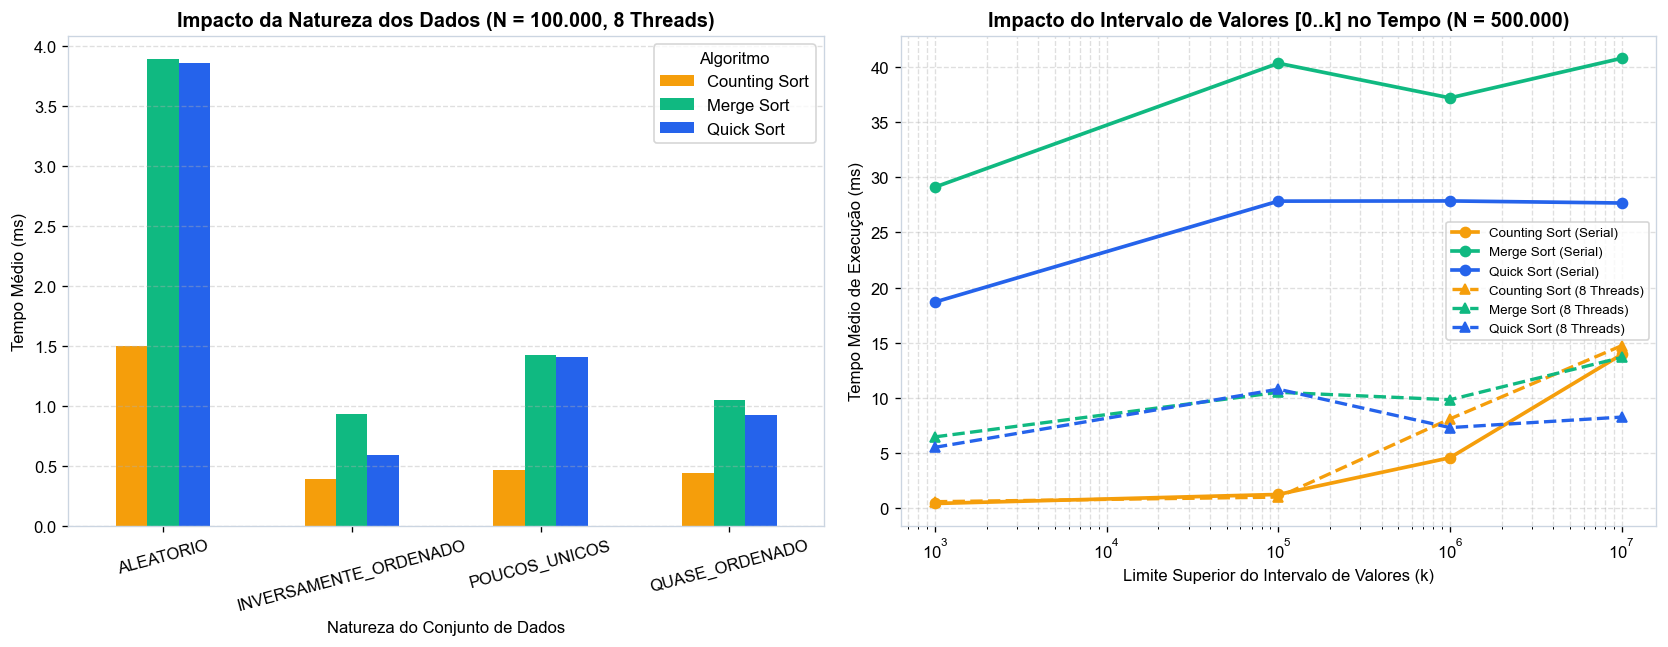

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Painel esquerdo: Natureza dos dados (N = 100.000, 8 threads, sem Bubble Sort para resolução visual)
ax1 = axes[0]
sub_nat = df_resumo[(df_resumo['Tamanho'] == 100000) & (df_resumo['Threads'] == 8) & (df_resumo['Algoritmo'] != 'Bubble Sort')]
pivot_nat = sub_nat.pivot(index='NaturezaDados', columns='Algoritmo', values='MediaMs')
pivot_nat.plot(kind='bar', ax=ax1, color=[cores.get(c, '#333') for c in pivot_nat.columns], rot=15)
ax1.set_title('Impacto da Natureza dos Dados (N = 100.000, 8 Threads)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Tempo Médio (ms)')
ax1.set_xlabel('Natureza do Conjunto de Dados')
ax1.grid(axis='y', linestyle='--', alpha=0.4)

# Painel direito: Intervalo de valores k em função do tempo (N = 500.000)
ax2 = axes[1]
sub_int = df_intervalos[df_intervalos['Threads'] == 1]
for alg, grupo in sub_int.groupby('Algoritmo'):
    grupo = grupo.sort_values('IntervaloMax')
    ax2.plot(
        grupo['IntervaloMax'], grupo['MediaMs'],
        label=f'{alg} (Serial)', color=cores.get(alg, '#333'), marker='o', linewidth=2.2
    )
sub_int_par = df_intervalos[df_intervalos['Threads'] == 8]
for alg, grupo in sub_int_par.groupby('Algoritmo'):
    grupo = grupo.sort_values('IntervaloMax')
    ax2.plot(
        grupo['IntervaloMax'], grupo['MediaMs'],
        label=f'{alg} (8 Threads)', color=cores.get(alg, '#333'), marker='^', linestyle='--', linewidth=2.0
    )
ax2.set_xscale('log')
ax2.set_title('Impacto do Intervalo de Valores [0..k] no Tempo (N = 500.000)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Limite Superior do Intervalo de Valores (k)')
ax2.set_ylabel('Tempo Médio de Execução (ms)')
ax2.grid(True, which='both', linestyle='--', alpha=0.4)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()